In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# Input Paths
DATA_DIR = r"/kaggle/input/datasets/tasneemselim/img-classification-competition/6- DRV/6- DRV/train"
TEST_IMAGES_DIR = r"/kaggle/input/datasets/tasneemselim/img-classification-competition/6- DRV/6- DRV/test/test_images"
SAMPLE_CSV_PATH = r"/kaggle/input/datasets/tasneemselim/img-classification-competition/6- DRV/6- DRV/test/predictions.csv" # The file with IDs and empty labels

# Output Path
OUTPUT_CSV_PATH = '/kaggle/working/DRV predictions.csv'

2026-05-03 19:46:05.110800: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777837565.391730      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777837565.471863      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777837566.164250      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777837566.164312      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777837566.164315      16 computation_placer.cc:177] computation placer alr

Found 11153 images belonging to 10 classes.
Found 2783 images belonging to 10 classes.
Starting Training...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-05-03 19:46:44.099948: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 184s 260ms/step - accuracy: 0.4350 - loss: 1.5767 - val_accuracy: 0.9713 - val_loss: 0.1351
Epoch 2/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 174s 249ms/step - accuracy: 0.8976 - loss: 0.3128 - val_accuracy: 0.9835 - val_loss: 0.0616
Epoch 3/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 182s 261ms/step - accuracy: 0.9374 - loss: 0.1827 - val_accuracy: 0.9910 - val_loss: 0.0374
Epoch 4/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 171s 245ms/step - accuracy: 0.9526 - loss: 0.1480 - val_accuracy: 0.9914 - val_loss: 0.0382
Epoch 5/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 177s 253ms/step - accuracy: 0.9653 - loss: 0.0997 - val_accuracy: 0.9903 - val_loss: 0.0327
Epoch 6/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 173s 248ms/step - accuracy: 0.9666 - loss: 0.0920 - val_accuracy: 0.9943 - val_loss: 0.0232
Epoch 7/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 176s 252ms/step - accuracy: 0.9681 - loss: 0.0914 - val_accuracy: 0.9925 - val_loss: 0.0278
Epoch 8/10
698/698 ━━━━━━━━━━━━━━━━━━━━ 171s 245ms/step - accuracy: 0.9751 -

Training Time: 26.51 minutes


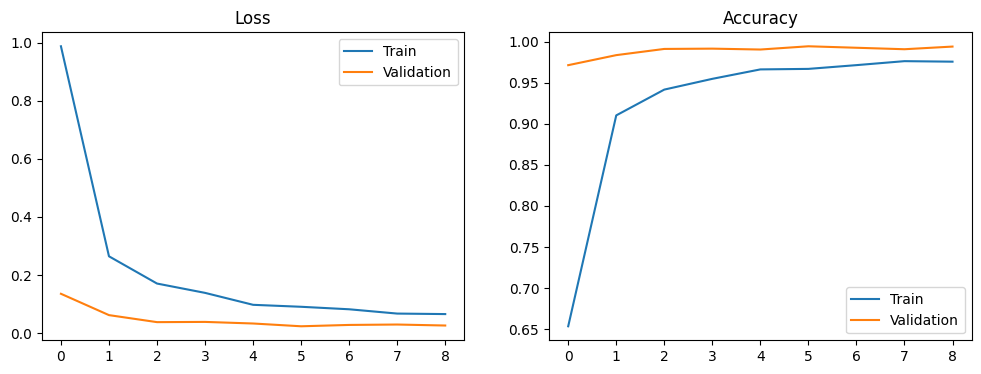

Starting Inference...
Submission file saved!


In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# =========================
# 1. Reproducibility
# =========================
SEED = 25
np.random.seed(SEED)
tf.random.set_seed(SEED)

# =========================
# 2. Parameters
# =========================
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
EPOCHS = 10
LR = 0.001
RUN_NAME = "run_1"
SEARCH_STRATEGY = "manual"

# =========================
# 3. Log Hyperparameters
# =========================
params = {
    "run": RUN_NAME,
    "batch_size": BATCH_SIZE,
    "learning_rate": LR,
    "epochs": EPOCHS,
    "search_strategy": SEARCH_STRATEGY
}
pd.DataFrame([params]).to_csv(f"{RUN_NAME}_params.csv", index=False)

# =========================
# 4. Data Loading
# =========================
datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)
classes = [str(i) for i in range (10)]

train_ds = datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED,
    classes=classes
)

val_ds = datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED,
    classes=classes
)

num_classes = len(train_ds.class_indices)

# =========================
# 5. Build Model (Clean)
# =========================
def build_model():
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(128, (3,3), activation='relu'),
        layers.MaxPooling2D(2,2),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),

        layers.Dense(num_classes, activation='softmax')
    ])
    return model

model = build_model()

# =========================
# 6. Compile
# =========================
opt = tf.keras.optimizers.Adam(learning_rate=LR)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

# =========================
# 7. Callbacks
# =========================
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# =========================
# 8. Training + Time Log
# =========================
print("Starting Training...")
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

total_time = (time.time() - start_time) / 60
print(f"Training Time: {total_time:.2f} minutes")

# Check time constraint
if total_time > 60:
    print("WARNING: Exceeded time limit!")

# =========================
# 9. Save Model + Logs
# =========================
model.save(f"{RUN_NAME}_model.h5")

history_df = pd.DataFrame(history.history)
history_df.to_csv(f"{RUN_NAME}_history.csv", index=False)

# =========================
# 10. Hardware Logging
# =========================
with open("hardware.txt", "w") as f:
    f.write(f"GPU: {tf.config.list_physical_devices('GPU')}\n")
    f.write(f"TensorFlow: {tf.__version__}\n")

# =========================
# 11. Plot Loss & Accuracy
# =========================
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title("Accuracy")
plt.legend()

plt.savefig(f"{RUN_NAME}_plot.png")
plt.show()

# =========================
# 12. Inference
# =========================
submission_df = pd.read_csv(SAMPLE_CSV_PATH)
predicted_labels = []

print("Starting Inference...")

for _, row in submission_df.iterrows():
    img_id = row['id']
    img_path = os.path.join(TEST_IMAGES_DIR, img_id)

    if os.path.exists(img_path):
        img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
        img_array = tf.keras.utils.img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        pred = model.predict(img_array, verbose=0)
        predicted_labels.append(np.argmax(pred))
    else:
        print(f"{img_id} not found")
        predicted_labels.append(0)

submission_df['label'] = predicted_labels
submission_df.to_csv(OUTPUT_CSV_PATH, index=False)

print("Submission file saved!")